In [7]:
import torch, sys
print("Python:", sys.version)
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Torch: 2.9.0+cu126
CUDA available: True
GPU: Tesla T4


In [8]:
# Install libs
!pip -q install "transformers>=4.44" "datasets>=2.20" "evaluate>=0.4" scikit-learn accelerate pandas


In [9]:
import pandas as pd

TWITTER_ALL = "/content/twitter_bert.csv"

# Quick peek
df = pd.read_csv(TWITTER_ALL)
print(df.shape)
df.head(3)


(20000, 2)


,cleaned_text,label
0,Its just over years since I was diagnosed with...,1
1,Its Sunday I need a break so Im planning to sp...,1
2,Awake but tired I need to sleep but my brain h...,1


In [10]:
from sklearn.model_selection import train_test_split

TEXT_COL, LABEL_COL = "cleaned_text", "label"
SEED = 42

# Stratified 70/10/20 split
train_tw, temp_tw = train_test_split(
    df, test_size=0.30, stratify=df[LABEL_COL], random_state=SEED
)
val_tw, test_tw = train_test_split(
    temp_tw, test_size=2/3, stratify=temp_tw[LABEL_COL], random_state=SEED
)

print("Twitter train:", train_tw.shape)
print("Twitter val  :", val_tw.shape)
print("Twitter test :", test_tw.shape)

# Save splits to disk
train_path = "/content/twitter_train.csv"
val_path   = "/content/twitter_val.csv"
test_path  = "/content/twitter_test.csv"
train_tw.to_csv(train_path, index=False)
val_tw.to_csv(val_path, index=False)
test_tw.to_csv(test_path, index=False)


Twitter train: (14000, 2)
Twitter val  : (2000, 2)
Twitter test : (4000, 2)


In [6]:
import os, json, random, numpy as np, torch
from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    EarlyStoppingCallback
)
import evaluate

# Config
MODEL_NAME = "bert-base-uncased"
OUTPUT_DIR = "/content/outputs/bert_twitter_only"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load datasets
dataset = load_dataset("csv", data_files={
    "train": train_path,
    "validation": val_path,
    "test": test_path,
})

# Ensure labels are ints
def coerce_label(ex):
    ex[LABEL_COL] = int(ex[LABEL_COL])
    return ex
dataset = dataset.map(coerce_label)

num_labels = len(set(dataset["train"][LABEL_COL]))
print("num_labels:", num_labels)

# Tokenizer / preprocess
tok = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
def preprocess(batch):
    return tok(batch[TEXT_COL], truncation=True, max_length=256)
tokenized = dataset.map(preprocess, batched=True, remove_columns=[TEXT_COL])

# Metrics
accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")
precision = evaluate.load("precision")
recall = evaluate.load("recall")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "f1":       f1.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "precision":precision.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall":   recall.compute(predictions=preds, references=labels, average="weighted")["recall"],
    }

# Model
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_labels)

# Precision (fp16/bf16) for speed
bf16_ok = torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8
fp16_ok = torch.cuda.is_available()

# Training args
args = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=50,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    save_total_limit=2,
    seed=SEED,
    report_to=["none"],
    fp16=(fp16_ok and not bf16_ok),
    bf16=bf16_ok,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    tokenizer=tok,
    data_collator=DataCollatorWithPadding(tokenizer=tok),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

trainer.train()

# Save best model + tokenizer
trainer.save_model(OUTPUT_DIR)
tok.save_pretrained(OUTPUT_DIR)
with open(f"{OUTPUT_DIR}/training_args.json", "w") as f:
    json.dump(vars(args), f, default=str, indent=2)

print("✅ Training complete. Model saved to:", OUTPUT_DIR)


Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/14000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-737377438.py:83: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.346300,0.306036,0.847000,0.846974,0.847235,0.847000
2,0.203300,0.386265,0.868500,0.868150,0.872451,0.868500
3,0.137200,0.502729,0.884500,0.884487,0.884670,0.884500
4,0.049500,0.609397,0.889000,0.888946,0.889755,0.889000
5,0.051400,0.695037,0.885000,0.884994,0.885075,0.885000


✅ Training complete. Model saved to: /content/outputs/bert_twitter_only


=== Twitter Test Metrics ===
accuracy: 0.8785
f1: 0.8784
precision: 0.8792
recall: 0.8785

=== Classification Report (Twitter Test) ===
              precision    recall  f1-score   support

           0     0.8955    0.8570    0.8758      2000
           1     0.8629    0.9000    0.8811      2000

    accuracy                         0.8785      4000
   macro avg     0.8792    0.8785    0.8784      4000
weighted avg     0.8792    0.8785    0.8784      4000



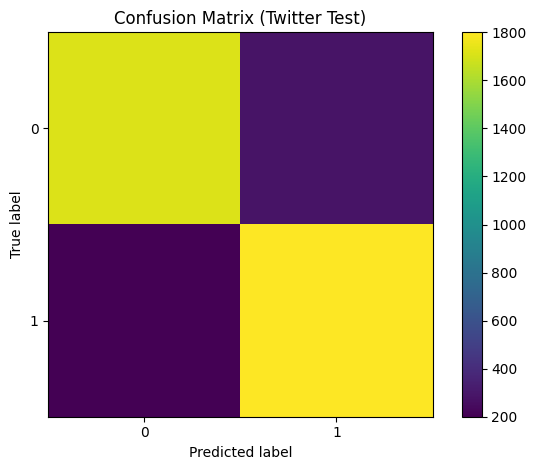

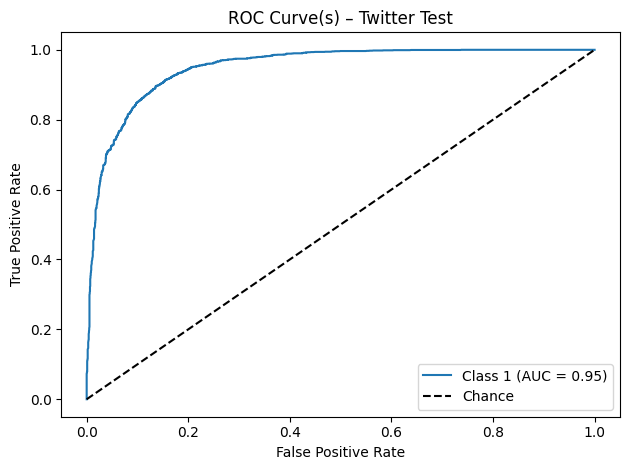

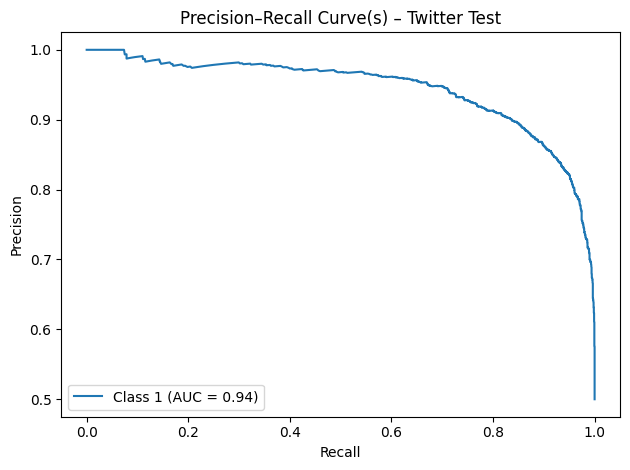

In [11]:
"""Evaluate on Twitter test with CM, PR, ROC"""

import numpy as np, json, pandas as pd
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Predict on tokenized test
pred = trainer.predict(tokenized["test"])
y_true = pred.label_ids
y_pred = pred.predictions.argmax(axis=-1)

# Stable softmax for probabilities
logits = pred.predictions
logits_shifted = logits - logits.max(axis=1, keepdims=True)
probs = np.exp(logits_shifted) / np.exp(logits_shifted).sum(axis=1, keepdims=True)

num_classes = probs.shape[1]
class_ids = np.arange(num_classes)

# ---------- Metrics (same as during training) ----------
test_metrics = compute_metrics((pred.predictions, y_true))
print("=== Twitter Test Metrics ===")
for k, v in test_metrics.items():
    print(f"{k}: {v:.4f}")

# Save metrics
with open(f"{OUTPUT_DIR}/metrics_test_twitter.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

# Per-class report
rep = classification_report(y_true, y_pred, digits=4)
print("\n=== Classification Report (Twitter Test) ===")
print(rep)
with open(f"{OUTPUT_DIR}/classification_report_twitter.txt", "w") as f:
    f.write(rep)

# ---------- 1) Confusion Matrix (CM) ----------
cm = confusion_matrix(y_true, y_pred)
np.savetxt(f"{OUTPUT_DIR}/confusion_matrix_twitter.csv", cm, fmt="%d", delimiter=",")

plt.figure()
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix (Twitter Test)")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar()
tick_marks = np.arange(num_classes)
plt.xticks(tick_marks, tick_marks)
plt.yticks(tick_marks, tick_marks)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrix_twitter.png", dpi=150)
plt.show()

# ---------- 2) ROC curves ----------
plt.figure()
if num_classes == 2:
    # Binary: use probability of class 1
    y_score = probs[:, 1]
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Class 1 (AUC = {roc_auc:.2f})")
else:
    # Multi-class: one-vs-rest ROC per class
    y_bin = label_binarize(y_true, classes=class_ids)
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"Class {i} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve(s) – Twitter Test")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_twitter.png", dpi=150)
plt.show()

# ---------- 3) Precision–Recall curves ----------
plt.figure()
if num_classes == 2:
    y_score = probs[:, 1]
    pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_score)
    pr_auc = auc(pr_recall, pr_precision)
    plt.plot(pr_recall, pr_precision, label=f"Class 1 (AUC = {pr_auc:.2f})")
else:
    y_bin = label_binarize(y_true, classes=class_ids)
    for i in range(num_classes):
        pr_precision, pr_recall, _ = precision_recall_curve(y_bin[:, i], probs[:, i])
        pr_auc = auc(pr_recall, pr_precision)
        plt.plot(pr_recall, pr_precision, label=f"Class {i} (AUC = {pr_auc:.2f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve(s) – Twitter Test")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/pr_twitter.png", dpi=150)
plt.show()



Evaluate on Twitter test

=== Twitter Test Metrics ===
accuracy: 0.8785
f1: 0.8784
precision: 0.8792
recall: 0.8785

=== Classification Report (Twitter Test) ===
              precision    recall  f1-score   support

           0     0.8955    0.8570    0.8758      2000
           1     0.8629    0.9000    0.8811      2000

    accuracy                         0.8785      4000
   macro avg     0.8792    0.8785    0.8784      4000
weighted avg     0.8792    0.8785    0.8784      4000



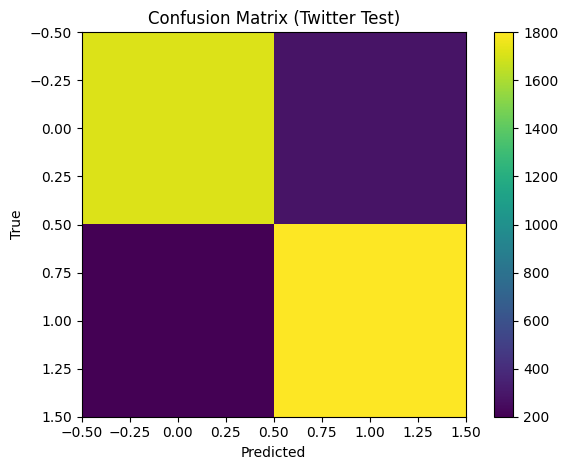


Saved detailed predictions to: /content/outputs/bert_twitter_only/twitter_test_predictions.csv
Artifacts saved in: /content/outputs/bert_twitter_only


In [12]:
import numpy as np, json, pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Predict on tokenized test
pred = trainer.predict(tokenized["test"])
y_true = pred.label_ids
y_pred = pred.predictions.argmax(axis=-1)

# Metrics (same as during training)
test_metrics = compute_metrics((pred.predictions, y_true))
print("=== Twitter Test Metrics ===")
for k, v in test_metrics.items():
    print(f"{k}: {v:.4f}")

# Save metrics
with open(f"{OUTPUT_DIR}/metrics_test_twitter.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

# Per-class report
rep = classification_report(y_true, y_pred, digits=4)
print("\n=== Classification Report (Twitter Test) ===")
print(rep)
with open(f"{OUTPUT_DIR}/classification_report_twitter.txt", "w") as f:
    f.write(rep)

# Confusion matrix (CSV + plot)
cm = confusion_matrix(y_true, y_pred)
np.savetxt(f"{OUTPUT_DIR}/confusion_matrix_twitter.csv", cm, fmt="%d", delimiter=",")

plt.figure()
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix (Twitter Test)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrix_twitter.png", dpi=150)
plt.show()

# Detailed predictions for error analysis
tw_test_df = pd.read_csv(test_path)
# stable softmax
probs = pred.predictions - pred.predictions.max(axis=1, keepdims=True)
probs = np.exp(probs) / np.exp(probs).sum(axis=1, keepdims=True)

out_df = tw_test_df.copy()
out_df["y_true"] = y_true
out_df["y_pred"] = y_pred
out_df["pred_confidence"] = probs.max(axis=1)
out_df["is_correct"] = (out_df["y_true"] == out_df["y_pred"]).astype(int)

out_file = f"{OUTPUT_DIR}/twitter_test_predictions.csv"
out_df.to_csv(out_file, index=False)
print(f"\nSaved detailed predictions to: {out_file}")
print(f"Artifacts saved in: {OUTPUT_DIR}")


EVALUATE TWITTER-TRAINED MODEL ON REDDIT TEST

Generating test split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/18668 [00:00<?, ? examples/s]

Map:   0%|          | 0/18668 [00:00<?, ? examples/s]

=== Reddit Test (evaluated by Twitter-trained model) ===
accuracy: 0.5343
f1: 0.4958
precision: 0.6845
recall: 0.5343

=== Classification Report (Reddit Test) ===
              precision    recall  f1-score   support

           0     0.8348    0.2792    0.4185     11202
           1     0.4589    0.9171    0.6117      7466

    accuracy                         0.5343     18668
   macro avg     0.6468    0.5982    0.5151     18668
weighted avg     0.6845    0.5343    0.4958     18668



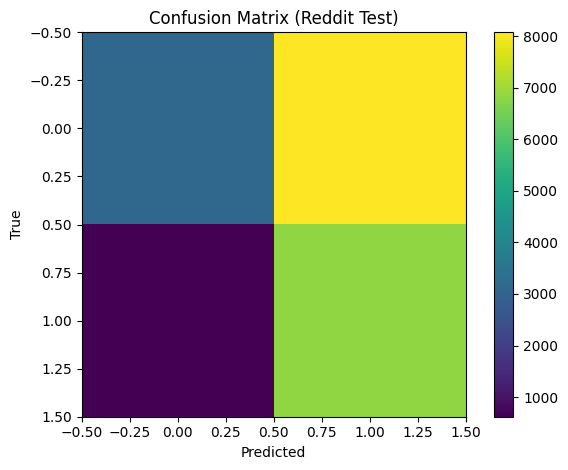


Saved Reddit predictions to: /content/outputs/bert_twitter_only/reddit_test_predictions_by_twitter_model.csv
All artifacts are in: /content/outputs/bert_twitter_only


In [13]:
import os, json, numpy as np, pandas as pd
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Path to your Reddit test CSV
REDDIT_TEST = "/content/reddit_bert_test.csv"   # <-- change if needed
TEXT_COL, LABEL_COL = "cleaned_text", "label"

# 1) Load Reddit test and coerce labels to ints
reddit_ds = load_dataset("csv", data_files={"test": REDDIT_TEST})

def coerce_label(ex):
    # If your Reddit CSV uses strings like "pos"/"neg", convert them to ints BEFORE this step.
    # Here we assume the file already uses integer labels 0..(num_labels-1).
    ex[LABEL_COL] = int(ex[LABEL_COL])
    return ex

reddit_ds = reddit_ds.map(coerce_label)

# 2) Tokenize with the SAME tokenizer used for training
reddit_tok = reddit_ds.map(
    lambda b: tok(b[TEXT_COL], truncation=True, max_length=256),
    batched=True,
    remove_columns=[TEXT_COL]
)

# 3) Predict
pred_rd = trainer.predict(reddit_tok["test"])
y_true_rd = pred_rd.label_ids
y_pred_rd = pred_rd.predictions.argmax(axis=-1)

# 4) Metrics (same function as training)
metrics_rd = compute_metrics((pred_rd.predictions, y_true_rd))
print("=== Reddit Test (evaluated by Twitter-trained model) ===")
for k, v in metrics_rd.items():
    print(f"{k}: {v:.4f}")

# 5) Save metrics/report/confusion matrix
os.makedirs(OUTPUT_DIR, exist_ok=True)
with open(f"{OUTPUT_DIR}/metrics_test_on_reddit.json", "w") as f:
    json.dump(metrics_rd, f, indent=2)

rep_rd = classification_report(y_true_rd, y_pred_rd, digits=4)
print("\n=== Classification Report (Reddit Test) ===")
print(rep_rd)
with open(f"{OUTPUT_DIR}/classification_report_test_on_reddit.txt", "w") as f:
    f.write(rep_rd)

cm_rd = confusion_matrix(y_true_rd, y_pred_rd)
np.savetxt(f"{OUTPUT_DIR}/confusion_matrix_test_on_reddit.csv", cm_rd, fmt="%d", delimiter=",")

plt.figure()
plt.imshow(cm_rd, interpolation="nearest")
plt.title("Confusion Matrix (Reddit Test)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrix_test_on_reddit.png", dpi=150)
plt.show()

# 6) Optional: detailed predictions CSV for error analysis
rd_df = pd.read_csv(REDDIT_TEST)
# numerically-stable softmax
probs = pred_rd.predictions - pred_rd.predictions.max(axis=1, keepdims=True)
probs = np.exp(probs) / np.exp(probs).sum(axis=1, keepdims=True)

out_rd = rd_df.copy()
out_rd["y_true"] = y_true_rd
out_rd["y_pred"] = y_pred_rd
out_rd["pred_confidence"] = probs.max(axis=1)
out_rd["is_correct"] = (out_rd["y_true"] == out_rd["y_pred"]).astype(int)

out_file_rd = f"{OUTPUT_DIR}/reddit_test_predictions_by_twitter_model.csv"
out_rd.to_csv(out_file_rd, index=False)
print(f"\nSaved Reddit predictions to: {out_file_rd}")
print(f"All artifacts are in: {OUTPUT_DIR}")


Map:   0%|          | 0/18668 [00:00<?, ? examples/s]

Map:   0%|          | 0/18668 [00:00<?, ? examples/s]

=== Reddit Test (evaluated by Twitter-trained model) ===
accuracy: 0.5343
f1: 0.4958
precision: 0.6845
recall: 0.5343

=== Classification Report (Reddit Test) ===
              precision    recall  f1-score   support

           0     0.8348    0.2792    0.4185     11202
           1     0.4589    0.9171    0.6117      7466

    accuracy                         0.5343     18668
   macro avg     0.6468    0.5982    0.5151     18668
weighted avg     0.6845    0.5343    0.4958     18668



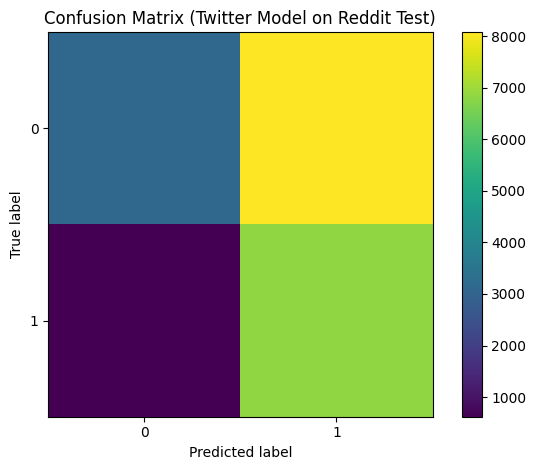

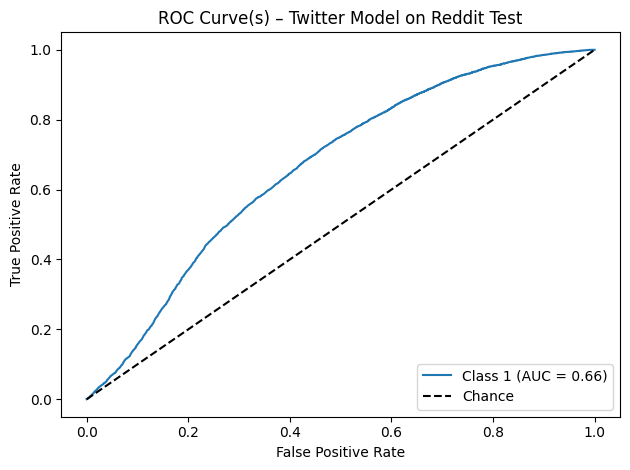

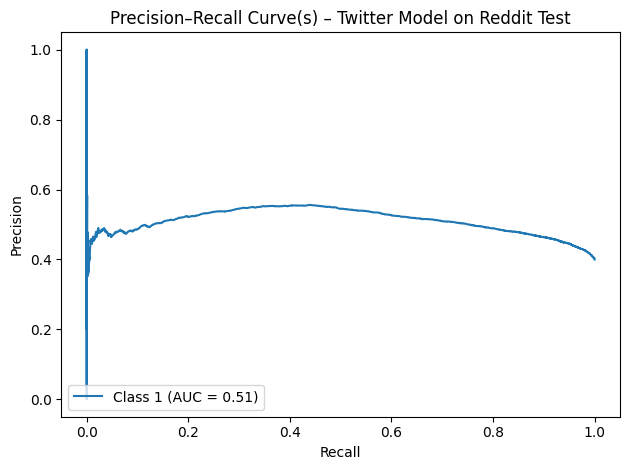


Saved Reddit predictions to: /content/outputs/bert_twitter_only/reddit_test_predictions_by_twitter_model.csv
All artifacts are in: /content/outputs/bert_twitter_only


In [14]:
"""EVALUATE TWITTER-TRAINED MODEL ON REDDIT TEST with CM, PR, ROC"""

import os, json, numpy as np, pandas as pd
from datasets import load_dataset
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Path to your Reddit test CSV
REDDIT_TEST = "/content/reddit_bert_test.csv"   # <-- change if needed
TEXT_COL, LABEL_COL = "cleaned_text", "label"

# 1) Load Reddit test and coerce labels to ints
reddit_ds = load_dataset("csv", data_files={"test": REDDIT_TEST})

def coerce_label(ex):
    ex[LABEL_COL] = int(ex[LABEL_COL])
    return ex

reddit_ds = reddit_ds.map(coerce_label)

# 2) Tokenize with the SAME tokenizer used for training
reddit_tok = reddit_ds.map(
    lambda b: tok(b[TEXT_COL], truncation=True, max_length=256),
    batched=True,
    remove_columns=[TEXT_COL]
)

# 3) Predict
pred_rd = trainer.predict(reddit_tok["test"])
y_true_rd = pred_rd.label_ids
y_pred_rd = pred_rd.predictions.argmax(axis=-1)

# Stable softmax for probabilities
logits_rd = pred_rd.predictions
logits_rd_shifted = logits_rd - logits_rd.max(axis=1, keepdims=True)
probs_rd = np.exp(logits_rd_shifted) / np.exp(logits_rd_shifted).sum(axis=1, keepdims=True)

num_classes_rd = probs_rd.shape[1]
class_ids_rd = np.arange(num_classes_rd)

# 4) Metrics
metrics_rd = compute_metrics((pred_rd.predictions, y_true_rd))
print("=== Reddit Test (evaluated by Twitter-trained model) ===")
for k, v in metrics_rd.items():
    print(f"{k}: {v:.4f}")

# Save metrics/report
os.makedirs(OUTPUT_DIR, exist_ok=True)
with open(f"{OUTPUT_DIR}/metrics_test_on_reddit.json", "w") as f:
    json.dump(metrics_rd, f, indent=2)

rep_rd = classification_report(y_true_rd, y_pred_rd, digits=4)
print("\n=== Classification Report (Reddit Test) ===")
print(rep_rd)
with open(f"{OUTPUT_DIR}/classification_report_test_on_reddit.txt", "w") as f:
    f.write(rep_rd)

# ---------- 1) Confusion Matrix (CM) ----------
cm_rd = confusion_matrix(y_true_rd, y_pred_rd)
np.savetxt(f"{OUTPUT_DIR}/confusion_matrix_test_on_reddit.csv", cm_rd, fmt="%d", delimiter=",")

plt.figure()
plt.imshow(cm_rd, interpolation="nearest")
plt.title("Confusion Matrix (Twitter Model on Reddit Test)")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar()
tick_marks_rd = np.arange(num_classes_rd)
plt.xticks(tick_marks_rd, tick_marks_rd)
plt.yticks(tick_marks_rd, tick_marks_rd)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrix_test_on_reddit.png", dpi=150)
plt.show()

# ---------- 2) ROC curves ----------
plt.figure()
if num_classes_rd == 2:
    y_score_rd = probs_rd[:, 1]
    fpr_rd, tpr_rd, _ = roc_curve(y_true_rd, y_score_rd)
    roc_auc_rd = auc(fpr_rd, tpr_rd)
    plt.plot(fpr_rd, tpr_rd, label=f"Class 1 (AUC = {roc_auc_rd:.2f})")
else:
    y_bin_rd = label_binarize(y_true_rd, classes=class_ids_rd)
    for i in range(num_classes_rd):
        fpr_rd, tpr_rd, _ = roc_curve(y_bin_rd[:, i], probs_rd[:, i])
        roc_auc_rd = auc(fpr_rd, tpr_rd)
        plt.plot(fpr_rd, tpr_rd, label=f"Class {i} (AUC = {roc_auc_rd:.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve(s) – Twitter Model on Reddit Test")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_reddit.png", dpi=150)
plt.show()

# ---------- 3) Precision–Recall curves ----------
plt.figure()
if num_classes_rd == 2:
    y_score_rd = probs_rd[:, 1]
    precision_rd, recall_rd, _ = precision_recall_curve(y_true_rd, y_score_rd)
    pr_auc_rd = auc(recall_rd, precision_rd)
    plt.plot(recall_rd, precision_rd, label=f"Class 1 (AUC = {pr_auc_rd:.2f})")
else:
    y_bin_rd = label_binarize(y_true_rd, classes=class_ids_rd)
    for i in range(num_classes_rd):
        precision_rd, recall_rd, _ = precision_recall_curve(y_bin_rd[:, i], probs_rd[:, i])
        pr_auc_rd = auc(recall_rd, precision_rd)
        plt.plot(recall_rd, precision_rd, label=f"Class {i} (AUC = {pr_auc_rd:.2f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve(s) – Twitter Model on Reddit Test")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/pr_reddit.png", dpi=150)
plt.show()

# ---------- Optional: detailed predictions ----------
rd_df = pd.read_csv(REDDIT_TEST)
out_rd = rd_df.copy()
out_rd["y_true"] = y_true_rd
out_rd["y_pred"] = y_pred_rd
out_rd["pred_confidence"] = probs_rd.max(axis=1)
out_rd["is_correct"] = (out_rd["y_true"] == out_rd["y_pred"]).astype(int)

out_file_rd = f"{OUTPUT_DIR}/reddit_test_predictions_by_twitter_model.csv"
out_rd.to_csv(out_file_rd, index=False)
print(f"\nSaved Reddit predictions to: {out_file_rd}")
print(f"All artifacts are in: {OUTPUT_DIR}")


In [15]:
# === Download fine-tuned model as a zip to your computer ===
import shutil
MODEL_DIR = "/content/outputs/bert_twitter_only"
ZIP_BASE = "/content/bert_twitter_model"   # no .zip extension here

# Create zip archive of the entire model directory
shutil.make_archive(ZIP_BASE, "zip", MODEL_DIR)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>